# Relearning the Count: Can a Neural Network Learn to Count Cards?

Blackjack card counters use systems like **Hi-Lo**. Every 2 through 6 that comes out adds +1 to the count, every 10, face card and ace subtracts 1, and 7, 8 and 9 count as 0. When the count is high, the remaining cards are more favorable to the player, so the counter bets more.

People figured out these card values decades ago using math and a lot of testing. I wanted to know: **if I give a neural network raw game data, can it figure out similar card values on its own? And can a reinforcement learning agent learn to bet more when the remaining cards are favorable, without ever being taught how card counting works?**

What's in this notebook:

1. A blackjack simulator I built from scratch, with casino rules and basic strategy, checked against the expected house edge
2. Testing whether card counting works using millions of simulated hands
3. Estimating the value of individual cards using linear regression
4. A **Keras** neural network that learns card values from raw shoe data
5. A **PyTorch** reinforcement learning agent that learns how much to bet
6. A head-to-head comparison of the betting methods on hands they haven't seen before
7. An analysis of how each strategy performs with a real bankroll

Everything is simulated, so no external dataset is needed.

In [5]:
import os
os.environ["KERAS_BACKEND"] = "torch"  # Use PyTorch as the Keras backend

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import keras

import blackjack as bj  # Custom blackjack simulator

sns.set_theme(style="whitegrid", context="notebook")

COLORS = {
    "Flat bet": "#9aa0a6",
    "Hi-Lo": "#d1495b",
    "Linear regression": "#3b6ea8",
    "Keras network": "#2a9d8f",
    "PyTorch RL agent": "#e9a23b"
}

DATA = "data"
os.makedirs(DATA, exist_ok=True)

print(
    "Keras", keras.__version__,
    "on", keras.backend.backend(),
    "| PyTorch", torch.__version__
)

Keras 3.13.2 on torch | PyTorch 2.11.0+cpu


## 1. The simulator

The simulator uses rules based on a typical Las Vegas Strip 6-deck game:

| Rule | Setting |
|---|---|
| Decks | 6, reshuffled after 75% of the shoe is dealt |
| Dealer | Hits soft 17 and peeks for blackjack |
| Blackjack pays | 3:2 |
| Doubling | Allowed on any first two cards, including after a split |
| Splitting | Once per hand, no re-splitting; split aces get one card each |
| Surrender | Not allowed |

The player always uses **basic strategy**, which gives the best play for each hand based on the player's cards and the dealer's upcard, without accounting for which cards have already been dealt. The full simulator is in `blackjack.py`.

Here's the strategy it uses for hard totals:

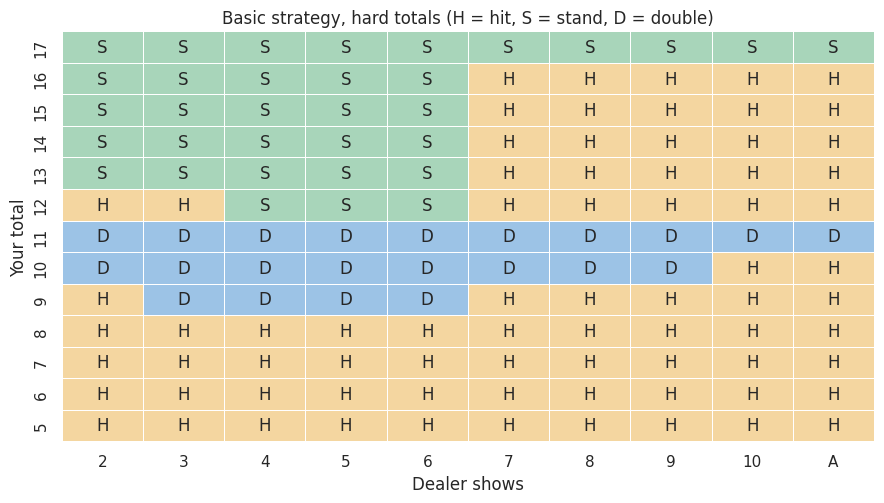

In [6]:
ups = list(range(2, 12))
rows = {}

for total in range(17, 4, -1):
    # Build a two-card hard hand with this total, avoiding pairs.
    a = min(total - 2, 10)
    cards = [a - 1, total - a - 1]

    rows[total] = [
        bj.basic_strategy(
            cards,
            up,
            can_double=True,
            can_split=False
        )
        for up in ups
    ]

chart = pd.DataFrame(
    rows,
    index=[str(u) if u < 11 else "A" for u in ups]
).T

chart.index.name = "Your total"
chart.columns.name = "Dealer shows"

colors = {"H": 0, "S": 1, "D": 2}

fig, ax = plt.subplots(figsize=(9, 5.2))

sns.heatmap(
    chart.apply(lambda col: col.map(colors)).astype(int),
    annot=chart,
    fmt="",
    cbar=False,
    linewidths=0.5,
    cmap=sns.color_palette(["#f4d6a0", "#a8d5ba", "#9cc3e6"]),
    ax=ax
)

ax.set_title("Basic strategy, hard totals (H = hit, S = stand, D = double)")

plt.tight_layout()
plt.show()

### Checking the simulator

Before trusting the results, I checked whether the simulator produces a reasonable house edge. With these rules and flat 1-unit bets, the house should keep a little under 1% of the total amount wagered.

I simulate 10 million rounds across 4 independent streams of shoes, split across CPU cores. The first 7.5 million rounds are used for training, and the remaining 2.5 million are held out for the final comparison. No model sees the test data during training. The results are saved to disk, so the simulation only needs to run once.

In [7]:
path = f"{DATA}/hands.npz"

if not os.path.exists(path):
    t = time.time()

    comp, profit = bj.parallel(
        bj._hands_job,
        [(2_500_000, s) for s in (11, 12, 13, 14)]
    )

    np.savez_compressed(path, comp=comp, profit=profit)
    print(f"Simulated in {time.time() - t:.0f}s")

hands = np.load(path)

X_all = bj.composition_features(hands["comp"])
y_all = hands["profit"]

N_TRAIN = 7_500_000

X_train, y_train = X_all[:N_TRAIN], y_all[:N_TRAIN]
X_test, y_test = X_all[N_TRAIN:], y_all[N_TRAIN:]

edge = y_all.mean()
se = y_all.std() / np.sqrt(len(y_all))

print(f"Rounds simulated: {len(y_all):,}")
print(
    f"Player edge with basic strategy, flat bets: {edge * 100:.2f}% "
    f"(95% CI {100 * (edge - 1.96 * se):.2f}% to "
    f"{100 * (edge + 1.96 * se):.2f}%)"
)
print(f"Standard deviation of one round: {y_all.std():.2f} units")

Simulated in 175s
Rounds simulated: 10,000,000
Player edge with basic strategy, flat bets: -0.78% (95% CI -0.85% to -0.71%)
Standard deviation of one round: 1.15 units


The player lost a little under 1% per round, which is in the expected range for a 6-deck game where the dealer hits soft 17 and re-splitting isn't allowed. The standard deviation was around 1.15 units per round, which is also in line with what I'd expect from blackjack. That gave me confidence that the simulator was working reasonably well before moving on.

## 2. Does counting actually work?

To test this, I calculated the Hi-Lo **true count** for each round by dividing the running count by the estimated number of decks remaining. Then I grouped rounds by true count and calculated the player's average result in each group.

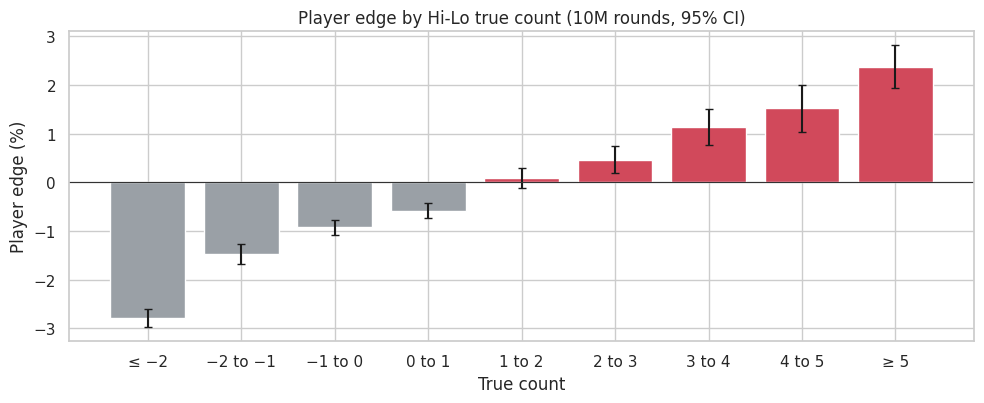

,edge_%,ci_%,share_of_rounds_%
tc,,,
≤ −2,-2.79,0.18,15.47
−2 to −1,-1.47,0.20,12.38
−1 to 0,-0.93,0.15,21.79
0 to 1,-0.58,0.15,23.74
1 to 2,0.09,0.21,11.78
2 to 3,0.46,0.28,6.49
3 to 4,1.14,0.37,3.67
4 to 5,1.52,0.48,2.10
≥ 5,2.38,0.43,2.57


In [8]:
tc = bj.hilo_true_count(X_all)

bins = [-np.inf, -2, -1, 0, 1, 2, 3, 4, 5, np.inf]
labels = [
    "≤ −2", "−2 to −1", "−1 to 0", "0 to 1",
    "1 to 2", "2 to 3", "3 to 4", "4 to 5", "≥ 5"
]

tc_bins = pd.cut(tc, bins=bins, labels=labels, right=False)

g = (
    pd.DataFrame({"tc": tc_bins, "profit": y_all})
    .groupby("tc", observed=True)["profit"]
)

by_tc = pd.DataFrame({
    "edge_%": g.mean() * 100,
    "ci_%": 1.96 * g.std() / np.sqrt(g.size()) * 100,
    "share_of_rounds_%": g.size() / len(y_all) * 100
})

fig, ax = plt.subplots(figsize=(10, 4.2))

cols = [
    "#d1495b" if value > 0 else "#9aa0a6"
    for value in by_tc["edge_%"]
]

ax.bar(
    by_tc.index.astype(str),
    by_tc["edge_%"],
    yerr=by_tc["ci_%"],
    color=cols,
    capsize=3
)

ax.axhline(0, color="#333", linewidth=0.8)
ax.set(
    title="Player edge by Hi-Lo true count (10M rounds, 95% CI)",
    xlabel="True count",
    ylabel="Player edge (%)"
)

plt.tight_layout()
plt.show()

by_tc.round(2)

Counting seems to work. At neutral counts, the house keeps its usual edge. Once the true count reaches around +2, the player starts to pull ahead, and at +5 or higher, the player's edge is over 2%.

The last column is what stood out to me: these favorable situations are rare. Most rounds happen at neutral or negative counts. That's why counters keep their bets small most of the time and increase them when the count is favorable.

## 3. What is each card worth? (linear regression)

Hi-Lo is a simplified system. It gives every low card a value of +1, every high card a value of −1 and ignores 7, 8 and 9. I wanted to see what value the data would assign to each card.

For each round, I described the shoe using 10 numbers, one for each card rank. Each number represents how many extra cards of that rank have been played, relative to a neutral shoe, per deck remaining. All zeros means a perfectly neutral shoe. I then fit a linear regression to predict the player's result from those 10 numbers. Each coefficient estimates how the player's expected result changes when the shoe has one more card of that rank missing, relative to the baseline.

One technical detail: the 10 numbers always add up to zero because cards removed from the shoe are no longer available to be dealt. This means the coefficients can't be uniquely determined without an extra constraint. I center the values so their average across a full deck is zero, giving the card values a consistent reference point.

In [9]:
def center(v):
    # Make a full deck's card values sum to zero
    return v - (bj.PER_DECK * v).sum() / 52


# Leave tens out of the regression to handle the sum-to-zero constraint.
# Their value is set to zero before centering.
A = np.c_[np.ones(N_TRAIN), X_train[:, :9]]

coef, *_ = np.linalg.lstsq(A, y_train, rcond=None)

resid_var = np.mean((y_train - A @ coef) ** 2)
cov = resid_var * np.linalg.inv(A.T @ A)

linear_values = center(np.r_[coef[1:], 0.0])

# Standard errors after centering the coefficients
M = (
    np.eye(10)[:, :9]
    - np.outer(np.ones(10), bj.PER_DECK[:9]) / 52
)

linear_se = np.sqrt(
    np.diag(M @ cov[1:, 1:] @ M.T)
)

values = pd.DataFrame({
    "Hi-Lo tag": bj.HI_LO,
    "Linear regression (% edge)": linear_values * 100,
    "± std. error": linear_se * 100
}, index=bj.RANK_LABELS)

values.index.name = "Card removed"

values.round(3)

,Hi-Lo tag,Linear regression (% edge),± std. error
Card removed,,,
A,-1,-0.518,0.054
2,1,0.447,0.054
3,1,0.436,0.054
4,1,0.560,0.054
5,1,0.745,0.054
6,1,0.399,0.054
7,0,0.308,0.054
8,0,0.026,0.054
9,0,-0.196,0.054


The first thing I checked was the signs, and they matched Hi-Lo: when low cards are gone, the player is better off, and when tens and aces are gone, the player is worse off. (A Hi-Lo tag of +1 means the player benefits when that card is dealt.)

The sizes weren't equal, though. The 5 stood out as the most valuable card to see leave the deck, and the 7 came out clearly positive even though Hi-Lo counts it as 0. I came back to this result after training the neural network.

## 4. Keras: can a neural network learn the card values?

The regression assumes the effect of each card is a straight line. A neural network doesn't have to make that assumption. It can learn nonlinear relationships and interactions between cards. The problem is that the signal is *tiny*. One round's result has a standard deviation of about 1.15 units, while the edge we're trying to detect changes by roughly 0.5 percentage points per card. A network trained on individual hands mostly sees noise. In my first attempts, it learned card values that were nowhere near what I expected.

**My fix was variance reduction.** Instead of using the result of one hand at each shoe position, I walk through real shoes and, at each position, play **16 independent hands** using fresh shuffles of the remaining cards. I then average their results. Averaging 16 independent outcomes reduces the standard deviation of the noise by a factor of 4 ($\sqrt{16}$), giving the network a cleaner target.

This takes about 10 million simulated hands to generate 600,000 training examples. The results are cached after the first run, so I don't have to generate them again.

In [10]:
path = f"{DATA}/states.npz"

if not os.path.exists(path):
    t = time.time()

    comp, avg = bj.parallel(
        bj._states_job,
        [(150_000, 16, s) for s in (101, 102, 103, 104)]
    )

    np.savez_compressed(path, comp=comp, avg=avg)
    print(f"Simulated in {time.time() - t:.0f}s")

states = np.load(path)

X_states = bj.composition_features(states["comp"])
y_states = states["avg"].reshape(-1, 1)

print(f"{len(y_states):,} shoe positions, each averaged over 16 hands")
print(
    f"Noise per example: {y_states.std():.3f} units "
    f"(vs {y_all.std():.3f} for a single hand)"
)

Simulated in 732s
600,000 shoe positions, each averaged over 16 hands
Noise per example: 0.289 units (vs 1.153 for a single hand)


The network itself is small, with two hidden layers of 16 neurons each. The output layer starts with zero weights and biases, so the network initially predicts zero rather than the average target. It only moves away from that as it learns from the data.

I trained it using the Adam optimizer, lowered the learning rate when the validation loss stopped improving and stopped early to avoid overfitting. I also trained three versions with different random seeds to check whether the card values were consistent or just a fluke.

In [11]:
def build_network(seed):
    keras.utils.set_random_seed(seed)

    model = keras.Sequential([
        keras.Input((10,)),
        keras.layers.Dense(16, activation="relu"),
        keras.layers.Dense(16, activation="relu"),
        keras.layers.Dense(
            1,
            kernel_initializer="zeros",
            bias_initializer=keras.initializers.Constant(float(y_all.mean()))
        )
    ])

    model.compile(
        optimizer=keras.optimizers.Adam(1e-3),
        loss="mse"
    )

    return model


def nn_card_values(model, X):
    # Average change in predicted edge when one extra card of each rank is removed
    base = model.predict(X, batch_size=65536, verbose=0).ravel()

    v = np.array([
        (
            model.predict(
                X + np.eye(10, dtype=np.float32)[r],
                batch_size=65536,
                verbose=0
            ).ravel() - base
        ).mean()
        for r in range(10)
    ])

    return center(v)


split = 480_000

callbacks = [
    keras.callbacks.ReduceLROnPlateau(
        factor=0.3,
        patience=2,
        min_lr=1e-6
    ),
    keras.callbacks.EarlyStopping(
        patience=6,
        restore_best_weights=True
    )
]

nets, histories, nn_values = [], [], []

# Use realistic shoe compositions to estimate the card values
probe = X_test[:20_000]

for seed in (0, 1, 2):
    t = time.time()

    m = build_network(seed)

    h = m.fit(
        X_states[:split],
        y_states[:split],
        validation_data=(
            X_states[split:],
            y_states[split:]
        ),
        batch_size=1024,
        epochs=60,
        verbose=0,
        callbacks=callbacks
    )

    nets.append(m)
    histories.append(h.history)
    nn_values.append(nn_card_values(m, probe))

    print(
        f"Seed {seed}: {len(h.history['loss'])} epochs, "
        f"best val MSE {min(h.history['val_loss']):.5f}, "
        f"{time.time() - t:.0f}s"
    )

nn_values = np.array(nn_values)
keras_net = nets[0]

Seed 0: 15 epochs, best val MSE 0.08345, 63s
Seed 1: 9 epochs, best val MSE 0.08345, 36s
Seed 2: 10 epochs, best val MSE 0.08345, 41s


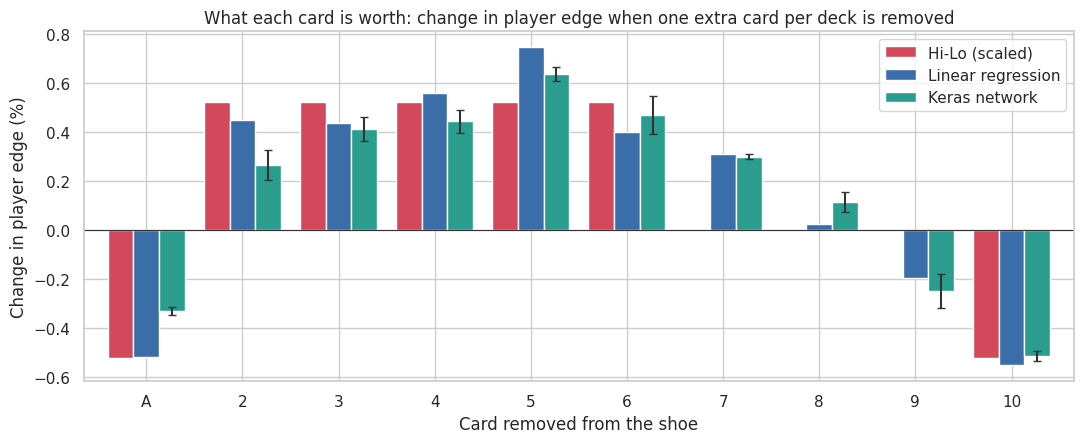

Correlation of Keras values with Hi-Lo tags: 0.905
Correlation of Keras values with linear regression: 0.977
Most valuable card to remove (Keras): 5


,Hi-Lo tag,Linear regression (% edge),± std. error,Keras network (% edge),Keras spread across seeds
Card removed,,,,,
A,-1,-0.518,0.054,-0.331,0.018
2,1,0.447,0.054,0.265,0.063
3,1,0.436,0.054,0.412,0.048
4,1,0.560,0.054,0.443,0.047
5,1,0.745,0.054,0.636,0.028
6,1,0.399,0.054,0.468,0.077
7,0,0.308,0.054,0.299,0.008
8,0,0.026,0.054,0.114,0.039
9,0,-0.196,0.054,-0.248,0.070


In [12]:
values["Keras network (% edge)"] = nn_values.mean(axis=0) * 100
values["Keras spread across seeds"] = nn_values.std(axis=0) * 100

# Scale Hi-Lo tags to the same size as the regression values for comparison
scale = (
    np.dot(bj.HI_LO, linear_values)
    / np.dot(bj.HI_LO, bj.HI_LO)
)

plot = pd.DataFrame({
    "Hi-Lo (scaled)": bj.HI_LO * scale * 100,
    "Linear regression": linear_values * 100,
    "Keras network": nn_values.mean(axis=0) * 100
}, index=bj.RANK_LABELS)

fig, ax = plt.subplots(figsize=(11, 4.6))

plot.plot.bar(
    ax=ax,
    color=[
        COLORS["Hi-Lo"],
        COLORS["Linear regression"],
        COLORS["Keras network"]
    ],
    width=0.8,
    rot=0
)

ax.errorbar(
    np.arange(10) + 0.267,
    nn_values.mean(axis=0) * 100,
    yerr=nn_values.std(axis=0) * 100,
    fmt="none",
    ecolor="#333",
    capsize=3
)

ax.axhline(0, color="#333", linewidth=0.8)

ax.set(
    title="What each card is worth: change in player edge when one extra card per deck is removed",
    xlabel="Card removed from the shoe",
    ylabel="Change in player edge (%)"
)

plt.tight_layout()
plt.show()

print(
    f"Correlation of Keras values with Hi-Lo tags: "
    f"{np.corrcoef(nn_values.mean(axis=0), bj.HI_LO)[0, 1]:.3f}"
)

print(
    f"Correlation of Keras values with linear regression: "
    f"{np.corrcoef(nn_values.mean(axis=0), linear_values)[0, 1]:.3f}"
)

print(
    f"Most valuable card to remove (Keras): "
    f"{bj.RANK_LABELS[nn_values.mean(axis=0).argmax()]}"
)

values.round(3)

**The network learned card values that closely resemble a counting system.** Without being given Hi-Lo values, it learned that low cards leaving the shoe help the player, while tens and aces leaving hurt. The correlation with Hi-Lo was about 0.9 (printed above). I also trained it with three different random seeds and got similar results each time, which suggests the pattern wasn't just a fluke of one run.

It also picked up some of the differences that the regression found, which Hi-Lo doesn't capture:

- **The 5 stood out as the most valuable card to remove.** Hi-Lo treats 2 through 6 equally, but the network estimated a stronger effect for the 5. Low cards affect the dealer's chances of improving stiff hands, though the exact value depends on the full game situation.
- **The 7 had a positive value.** Hi-Lo ignores it, but the network estimated that removing a 7 helps the player.
- **The 9 had a small negative value**, even though Hi-Lo counts it as 0.

These differences are the kind of thing more advanced counting systems try to capture by assigning different values to different cards. Hi-Lo gives up some detail in exchange for being simple enough to use at a casino table.

## 5. PyTorch: can an agent learn *when to bet more*?

Knowing the card values is only half of card counting. The other half is using that information to decide how much to bet. For this, I used **reinforcement learning** in PyTorch.

The agent sees the same 10 numbers describing the shoe and chooses a bet of 1, 2, 4 or 8 units. It then plays one hand using basic strategy and receives its profit or loss as the reward. I never give it the Hi-Lo count, the true count or the player's edge. It only sees the shoe features, its chosen bet and the outcome.

I trained it using **REINFORCE**, a policy-gradient algorithm. The network outputs a probability for each bet size. After each batch of hands, the training process adjusts those probabilities based on the rewards, making bets that perform better than expected more likely in similar situations. Since blackjack outcomes are noisy, it takes millions of hands for a useful pattern to emerge.

In [13]:
torch.manual_seed(0)

BETS = torch.tensor([1.0, 2.0, 4.0, 8.0])

policy = torch.nn.Sequential(
    torch.nn.Linear(10, 32),
    torch.nn.ReLU(),
    torch.nn.Linear(32, 4)
)

with torch.no_grad():
    # Equal initial probabilities for all four bet sizes
    policy[-1].weight.zero_()
    policy[-1].bias.zero_()

optimizer = torch.optim.Adam(policy.parameters(), lr=3e-4)

Xt = torch.tensor(X_train)
yt = torch.tensor(y_train)

# Monitor performance on hands from the training period
X_val = X_train[-500_000:]
y_val = y_train[-500_000:]
tc_val = bj.hilo_true_count(X_val)


def agent_bets(X):
    with torch.no_grad():
        actions = policy(torch.tensor(X)).argmax(dim=1)
        return BETS.numpy()[actions.numpy()]


BATCH = 4096
EPOCHS = 8
log = []

t = time.time()

for epoch in range(EPOCHS):
    perm = torch.randperm(len(yt))

    for i in range(0, len(yt) - BATCH, BATCH):
        idx = perm[i:i + BATCH]

        dist = torch.distributions.Categorical(
            logits=policy(Xt[idx])
        )

        action = dist.sample()
        reward = BETS[action] * yt[idx]

        # Compare each reward with the average reward in the batch
        advantage = reward - reward.mean()

        loss = (
            -(dist.log_prob(action) * advantage).mean()
            - 1e-3 * dist.entropy().mean()
        )

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

    b = agent_bets(X_val)

    log.append({
        "epoch": epoch + 1,
        "avg bet": b.mean(),
        "EV per 100 rounds": (b * y_val).mean() * 100,
        **{
            f"bet @ TC {k}": b[
                (tc_val >= k) & (tc_val < k + 1)
            ].mean()
            for k in (0, 2, 4)
        }
    })

    print(
        f"Epoch {epoch + 1}: "
        f"avg bet {b.mean():.2f}, "
        f"EV {(b * y_val).mean() * 100:+.2f} units/100 rounds "
        f"({time.time() - t:.0f}s)"
    )

log = pd.DataFrame(log).set_index("epoch")

Epoch 1: avg bet 1.01, EV -0.89 units/100 rounds (11s)
Epoch 2: avg bet 1.23, EV -0.66 units/100 rounds (21s)
Epoch 3: avg bet 1.66, EV -0.05 units/100 rounds (32s)
Epoch 4: avg bet 1.97, EV +0.01 units/100 rounds (43s)
Epoch 5: avg bet 2.00, EV -0.18 units/100 rounds (54s)
Epoch 6: avg bet 2.12, EV +0.12 units/100 rounds (64s)
Epoch 7: avg bet 2.26, EV +0.20 units/100 rounds (75s)
Epoch 8: avg bet 2.36, EV +0.34 units/100 rounds (86s)


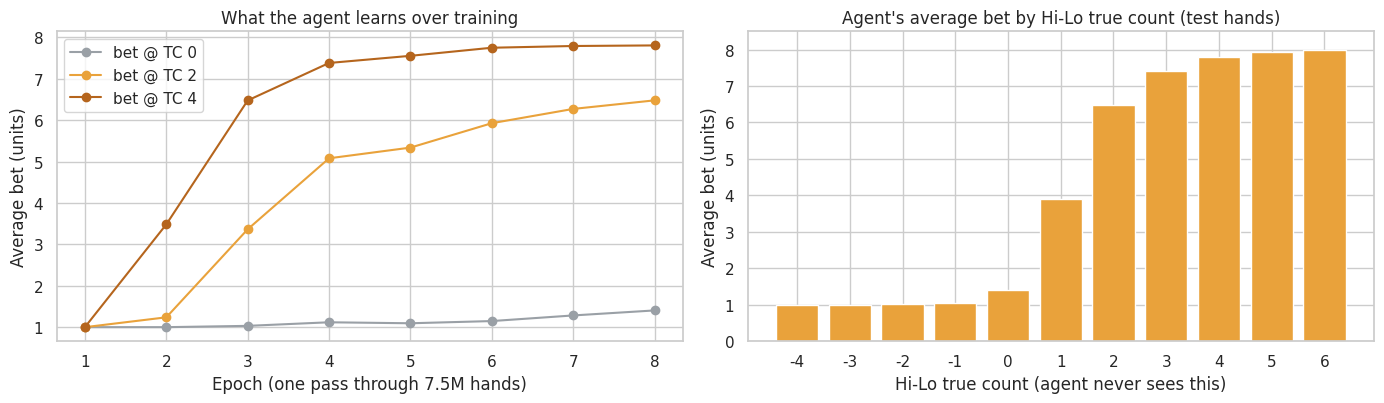

In [14]:
tc_test = bj.hilo_true_count(X_test)
agent_test_bets = agent_bets(X_test)

tc_grid = np.arange(-4, 7)

avg_bet = [
    agent_test_bets[
        (tc_test >= k) & (tc_test < k + 1)
    ].mean()
    for k in tc_grid
]

fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))

log[
    ["bet @ TC 0", "bet @ TC 2", "bet @ TC 4"]
].plot(
    ax=axes[0],
    marker="o",
    color=["#9aa0a6", "#e9a23b", "#b5651d"]
)

axes[0].set(
    title="What the agent learns over training",
    xlabel="Epoch (one pass through 7.5M hands)",
    ylabel="Average bet (units)"
)

axes[1].bar(
    tc_grid.astype(str),
    avg_bet,
    color=COLORS["PyTorch RL agent"]
)

axes[1].set(
    title="Agent's average bet by Hi-Lo true count (test hands)",
    xlabel="Hi-Lo true count (agent never sees this)",
    ylabel="Average bet (units)",
    ylim=(0, 8.5)
)

plt.tight_layout()
plt.show()

**The agent learned a betting pattern similar to card counting.** At the start of training, it bet the same amount across shoe compositions. Over the next few epochs, it started keeping bets smaller when the shoe was neutral or unfavorable and increasing them when the remaining cards were more favorable to the player. In the right-hand chart, I grouped its bets by Hi-Lo true count, which the agent never sees. The average bet rises with the count, suggesting it learned a pattern similar to the one card counters use, just from wins and losses.

## 6. Head-to-head on unseen hands

Now for the main comparison: 2.5 million rounds from simulated shoes held out from model training. Each method uses the same betting range of 1 to 8 units.

| Method | How it decides the bet |
|---|---|
| **Flat bet** | Always bets 1 unit |
| **Hi-Lo** | Converts the true count into an estimated edge, fitted using training data, then applies the shared betting rule |
| **Linear regression** | Estimates the edge using the regression from Section 3, then applies the shared betting rule |
| **Keras network** | Estimates the edge using the neural network, then applies the shared betting rule |
| **PyTorch RL agent** | Chooses its own bet directly |

The shared betting rule is 1 unit when the estimated edge is 0 or below, 2 units when it is above 0%, 4 units when it is above 0.5% and 8 units when it is above 1%.

Because the player's playing strategy stays the same regardless of the bet size, each method can be evaluated on the same simulated outcomes. This makes the comparison more direct and reduces noise when comparing the methods. However, the results are still estimates, and rounds from the same shoe may be correlated.

Hi-Lo calibration: each +1 true count adds 0.53% to the player's edge


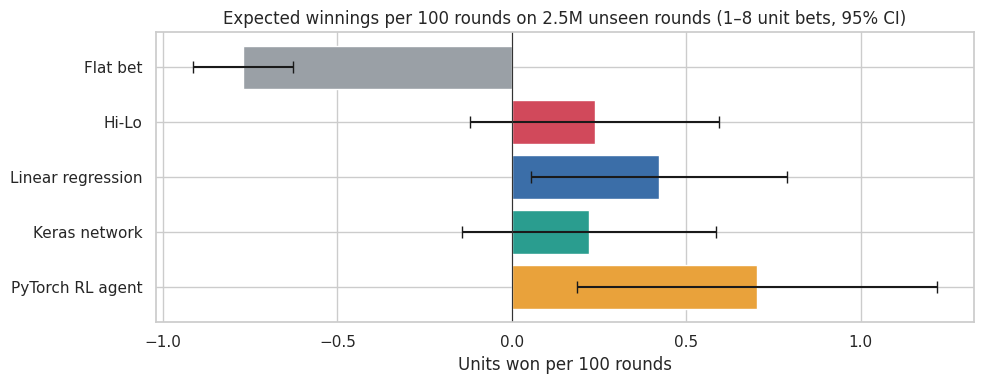

,EV per 100 rounds (units),± 95% CI,Return per unit bet (%),Average bet,vs Hi-Lo (units/100),vs Hi-Lo ± 95% CI
method,,,,,,
Flat bet,-0.771,0.143,-0.771,1.000,-1.009,0.279
Hi-Lo,0.238,0.357,0.138,1.728,0.000,0.000
Linear regression,0.421,0.366,0.238,1.768,0.183,0.120
Keras network,0.221,0.364,0.124,1.790,-0.017,0.152
PyTorch RL agent,0.702,0.516,0.296,2.376,0.464,0.298


In [15]:
def ramp(edge):
    return np.select(
        [edge > 0.01, edge > 0.005, edge > 0],
        [8.0, 4.0, 2.0],
        default=1.0
    )


tc_train = bj.hilo_true_count(X_train)

# Fit a linear relationship between true count and player edge
hl_fit = np.polyfit(tc_train, y_train, 1)

print(
    f"Hi-Lo calibration: each +1 true count adds "
    f"{hl_fit[0] * 100:.2f}% to the player's edge"
)


bets = {
    "Flat bet": np.ones(len(y_test)),
    "Hi-Lo": ramp(np.polyval(hl_fit, tc_test)),
    "Linear regression": ramp(
        coef[0] + X_test[:, :9] @ coef[1:]
    ),
    "Keras network": ramp(
        keras_net.predict(
            X_test,
            batch_size=65536,
            verbose=0
        ).ravel()
    ),
    "PyTorch RL agent": agent_test_bets
}


rows = []

for name, b in bets.items():
    win = b * y_test

    # Compare against Hi-Lo on the same test rounds
    diff = win - bets["Hi-Lo"] * y_test

    rows.append({
        "method": name,
        "EV per 100 rounds (units)": win.mean() * 100,
        "± 95% CI": (
            1.96 * win.std() / np.sqrt(len(win)) * 100
        ),
        "Return per unit bet (%)": (
            win.sum() / b.sum() * 100
        ),
        "Average bet": b.mean(),
        "vs Hi-Lo (units/100)": diff.mean() * 100,
        "vs Hi-Lo ± 95% CI": (
            1.96 * diff.std() / np.sqrt(len(diff)) * 100
        )
    })


results = pd.DataFrame(rows).set_index("method")

fig, ax = plt.subplots(figsize=(10, 4))

ax.barh(
    results.index,
    results["EV per 100 rounds (units)"],
    xerr=results["± 95% CI"],
    color=[COLORS[m] for m in results.index],
    capsize=4
)

ax.axvline(0, color="#333", linewidth=0.8)
ax.invert_yaxis()

ax.set(
    title="Expected winnings per 100 rounds on 2.5M unseen rounds (1–8 unit bets, 95% CI)",
    xlabel="Units won per 100 rounds"
)

plt.tight_layout()
plt.show()

results.round(3)

The first thing I noticed was that every counting method did better than flat betting. Flat betting lost about 0.8 units per 100 rounds, while all four counting methods finished ahead of it. The exact profit estimates still have fairly wide confidence intervals, even with 2.5 million rounds, because blackjack outcomes are noisy and bets range from 1 to 8 units. The paired "vs Hi-Lo" comparisons are tighter because they compare the methods on the same hands, reducing some of the noise from luck.

Here's what stood out in the paired comparison:

- **Linear regression beats Hi-Lo.** If the confidence interval for the difference stays above zero, that is evidence of a statistically clear improvement. Giving each card its own estimated value, including the 5, 7 and 9, appears to capture information that Hi-Lo leaves out.
- **The Keras network performs about as well as Hi-Lo.** It learned a similar pattern, but its estimated card values were less precise than the regression's. When I compared the values, the network appeared to underweight the ace and the 2, which may help explain why it didn't match the regression's performance.
- **The RL agent performs best on expected winnings per 100 rounds.** It also bets more on average, about 2.4 units compared with 1.7 for Hi-Lo, because it learns its own betting policy rather than using the shared ramp. Return per unit bet gives another perspective on the comparison, and the agent also ranks highest on that measure in my results.

The calibration check below tests whether the estimated edges match the results observed on held-out data. If a model predicts a 1% edge, its predicted advantage should be close to the realized average over enough rounds. The estimates will still have some uncertainty.

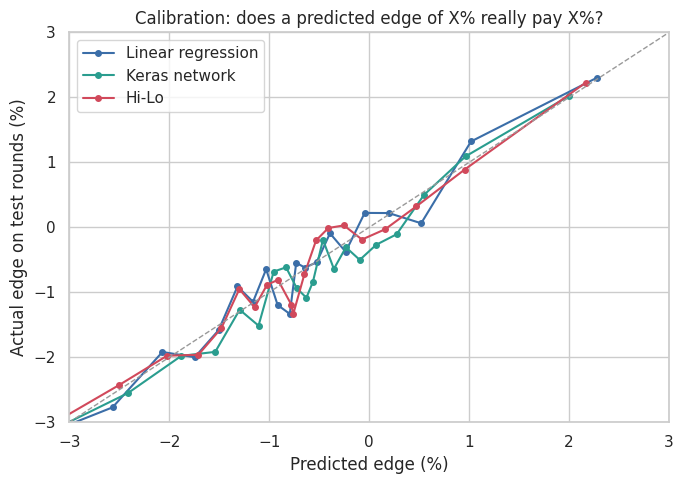

Linear regression  top 10% of rounds: predicted +1.65%, actual +1.81%
Keras network      top 10% of rounds: predicted +1.48%, actual +1.56%
Hi-Lo              top 10% of rounds: predicted +1.56%, actual +1.56%


In [16]:
# How well calibrated is each model's predicted edge?
# Group test rounds by predicted edge and compare with actual results.

preds = {
    "Linear regression": coef[0] + X_test[:, :9] @ coef[1:],
    "Keras network": keras_net.predict(
        X_test, batch_size=65536, verbose=0
    ).ravel(),
    "Hi-Lo": np.polyval(hl_fit, tc_test)
}

fig, ax = plt.subplots(figsize=(7, 5))
calib = {}

for name, p in preds.items():
    q = pd.qcut(p, 20, labels=False, duplicates="drop")

    df = (
        pd.DataFrame({
            "pred": p,
            "real": y_test,
            "q": q
        })
        .groupby("q", observed=True)
        .agg(
            pred=("pred", "mean"),
            real=("real", "mean"),
            n=("real", "size")
        )
    ) * 100

    calib[name] = df

    ax.plot(
        df["pred"],
        df["real"],
        "o-",
        color=COLORS[name],
        label=name,
        markersize=4
    )

lim = [-3, 3]
ax.plot(lim, lim, "--", color="#999", linewidth=1)

ax.set(
    xlim=lim,
    ylim=lim,
    xlabel="Predicted edge (%)",
    ylabel="Actual edge on test rounds (%)",
    title="Calibration: does a predicted edge of X% really pay X%?"
)

ax.legend()
plt.tight_layout()
plt.show()

for name, p in preds.items():
    cutoff = np.quantile(p, 0.90)
    mask = p >= cutoff

    print(
        f"{name:18s} top 10% of rounds: "
        f"predicted {p[mask].mean() * 100:+.2f}%, "
        f"actual {y_test[mask].mean() * 100:+.2f}%"
    )

All three models followed the diagonal reasonably closely, suggesting that their predicted edges were broadly consistent with the results on the held-out test rounds.

The more interesting difference was *which* rounds each model identified as the most favorable. The regression's top 10% of predicted rounds had a higher actual average result than the corresponding groups for Hi-Lo and the Keras network. This helps explain why the regression performed better in the betting test.

One possible reason is that the regression captured differences between individual card values that Hi-Lo ignores, while the neural network may need more training data to estimate those smaller effects reliably. Generating more simulated data or averaging more hands per shoe position could help the network, although I'd need to test that to know whether it actually closes the gap.

## 7. What this means for an actual bankroll

An edge of a fraction of a unit per 100 rounds is small compared with the swings. Even at flat bets, the standard deviation of a single round is over 1 unit, and it gets much larger when bets increase to 8 units.

To make the results more concrete, I split the 2.5 million held-out test rounds into sessions of 10,000 rounds and tracked how much each method won or lost in each session. At roughly 100 rounds per hour, a 10,000-round session represents about 100 hours of play. I then compared the distribution of session outcomes to see how often each method finished ahead or behind.

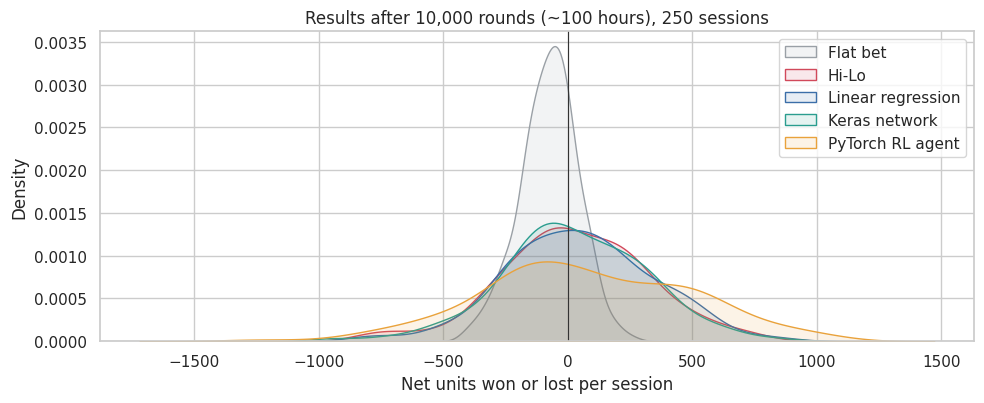

,average result (units),median (units),chance of finishing behind (%),worst session (units),best session (units)
Flat bet,-77.1,-65.8,76.0,-407.5,253.0
Hi-Lo,23.8,22.5,48.4,-812.5,786.5
Linear regression,42.1,44.2,46.8,-825.5,880.0
Keras network,22.1,-0.2,50.0,-948.0,834.0
PyTorch RL agent,70.2,49.5,45.6,-1301.0,1052.0


In [17]:
SESSION = 10_000
n_sessions = len(y_test) // SESSION
n_used = n_sessions * SESSION

methods = [
    "Flat bet",
    "Hi-Lo",
    "Linear regression",
    "Keras network",
    "PyTorch RL agent"
]

session_results = {
    name: (bets[name] * y_test)[:n_used]
        .reshape(n_sessions, SESSION)
        .sum(axis=1)
    for name in methods
}

fig, ax = plt.subplots(figsize=(10, 4.2))

for name, r in session_results.items():
    sns.kdeplot(
        r,
        ax=ax,
        label=name,
        color=COLORS[name],
        fill=True,
        alpha=0.12
    )

ax.axvline(0, color="#333", linewidth=0.8)

ax.set(
    title=f"Results after {SESSION:,} rounds (~100 hours), {n_sessions} sessions",
    xlabel="Net units won or lost per session",
    ylabel="Density"
)

ax.legend()
plt.tight_layout()
plt.show()

summary = pd.DataFrame({
    name: {
        "average result (units)": r.mean(),
        "median (units)": np.median(r),
        "chance of finishing behind (%)": (r < 0).mean() * 100,
        "worst session (units)": r.min(),
        "best session (units)": r.max()
    }
    for name, r in session_results.items()
}).T

summary.round(1)

This is the part that doesn't show up in movies. Even with a positive expected edge, about half of the 100-hour sessions for Hi-Lo and the Keras network still finished behind, compared with roughly three quarters for flat betting. The worst sessions with a 1–8 bet spread were also about twice as bad as those with flat betting.

A counter can play for 100 hours and still lose. Increasing bets when the shoe looks favorable can improve expected returns, but it also makes the swings bigger. The advantage only becomes meaningful over a long period of play, with a bankroll large enough to withstand losing stretches. And casinos can ask counters to leave, which this simulation doesn't account for.

## Summary

In [18]:
print("KEY RESULTS (printed from the analysis above)")
print(f"• House edge with basic strategy (10M rounds): {-y_all.mean()*100:.2f}%")
print(
    f"• Player edge at true count ≥ +5: "
    f"{by_tc['edge_%'].iloc[-1]:+.2f}% "
    f"(only {by_tc['share_of_rounds_%'].iloc[-1]:.1f}% of rounds)"
)
print(
    f"• Keras card values vs Hi-Lo tags, correlation: "
    f"{np.corrcoef(nn_values.mean(0), bj.HI_LO)[0, 1]:.2f}; "
    f"most valuable card to remove: "
    f"{bj.RANK_LABELS[nn_values.mean(0).argmax()]}"
)
print(
    f"• RL agent's average bet: "
    f"{agent_test_bets.mean():.2f} units overall"
)
print(
    f"  Average bet at TC 0: {avg_bet[tc_grid.tolist().index(0)]:.1f} units; "
    f"at TC +4: {avg_bet[tc_grid.tolist().index(4)]:.1f} units"
)

for m in results.index:
    print(
        f"• {m:18s} "
        f"{results.loc[m, 'EV per 100 rounds (units)']:+.2f} units per 100 rounds"
    )

KEY RESULTS (printed from the analysis above)
• House edge with basic strategy (10M rounds): 0.78%
• Player edge at true count ≥ +5: +2.38% (only 2.6% of rounds)
• Keras card values vs Hi-Lo tags, correlation: 0.90; most valuable card to remove: 5
• RL agent's average bet: 2.38 units overall
  Average bet at TC 0: 1.4 units; at TC +4: 7.8 units
• Flat bet           -0.77 units per 100 rounds
• Hi-Lo              +0.24 units per 100 rounds
• Linear regression  +0.42 units per 100 rounds
• Keras network      +0.22 units per 100 rounds
• PyTorch RL agent   +0.70 units per 100 rounds


### What I found

- A neural network given only raw shoe data **learned a pattern similar to card counting**. It recovered the broad Hi-Lo pattern and estimated some of the finer differences between cards: the 5 mattered most, the 7 had a positive value and the 9 had a slightly negative value.
- The key that made this work was **variance reduction**. Averaging 16 hands per shoe position reduced the noise in the training targets enough to reveal the signal. Training on individual hands mostly learned noise.
- A reinforcement learning agent that was **never given a count or an estimated edge** learned to raise its bets as the shoe became more favorable. Under this simulator and betting setup, it achieved a positive expected return.
- In the betting test, linear regression outperformed Hi-Lo, while the Keras network performed about as well as Hi-Lo. Learning the general pattern wasn't enough. Estimating the card values precisely enough to improve betting decisions mattered too.
- The edge was small compared with the swings. Even in a 100-hour simulated session, a counter could finish behind.

### Limitations

- The player always used basic strategy. Real counters can also change how they play certain hands at high counts, such as standing on 16 against a dealer's 10. These count-based deviations could add another source of edge.
- I tested one set of rules and one betting range. Changing shoe penetration, deck count or bet spread could change both the expected return and the risk.
- The simulation doesn't model casino countermeasures, such as shuffling early or asking suspected counters to leave.

### What I'd try next

- Let the RL agent learn **playing decisions** as well as bet sizes, then check whether it discovers known count-based deviations on its own.
- Test **Kelly-style bet sizing**, which scales bets according to the estimated edge and bankroll, and compare bankroll growth and risk of ruin with the fixed betting ramp.
- Test different levels of **shoe penetration** to measure how much dealing deeper into the shoe improves the value of counting.